<a href="https://colab.research.google.com/github/saichandanss2190/ITA0615-Machine-Learning-192312190-/blob/main/Exp_14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Dataset Preview ---


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422



Training Random Forest Regressor model...

--- Model Performance Metrics ---
Mean Absolute Error (MAE): 0.3274 ($100k)
Mean Squared Error (MSE):  0.2552
Root Mean Squared Error (RMSE): 0.5051 ($100k)
R-squared (R2) Score:      0.8053


/tmp/ipykernel_3642/2131758509.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=feature_names[indices], ax=axes[1], palette='viridis')


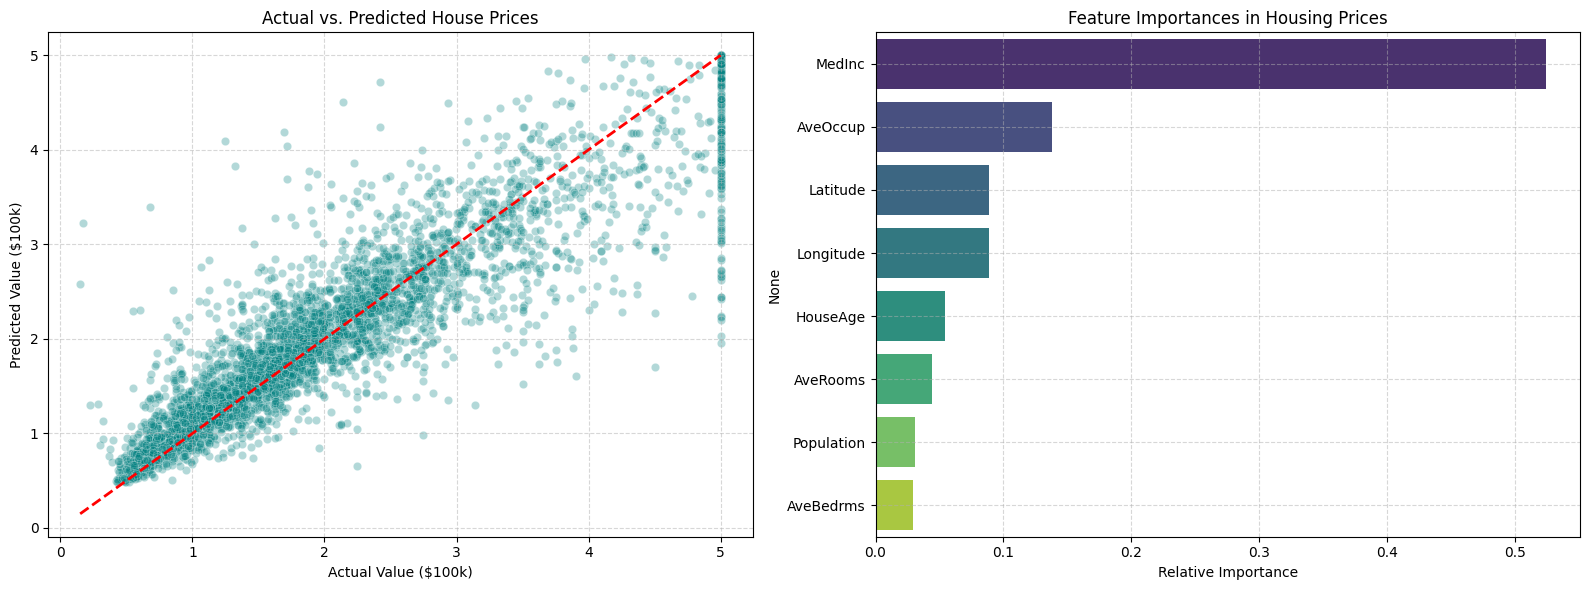

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Load Dataset
housing = fetch_california_housing(as_frame=True)
df = housing.frame

# Display data overview
print("--- Dataset Preview ---")
display(df.head())

# 2. Split Features and Target
X = df.drop(columns=['MedHouseVal'])
y = df['MedHouseVal']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Scale Features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Train Model
print("\nTraining Random Forest Regressor model...")
model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_train_scaled, y_train)

# 5. Predict and Evaluate
y_pred = model.predict(X_test_scaled)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n--- Model Performance Metrics ---")
print(f"Mean Absolute Error (MAE): {mae:.4f} ($100k)")
print(f"Mean Squared Error (MSE):  {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f} ($100k)")
print(f"R-squared (R2) Score:      {r2:.4f}")

# 6. Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot Actual vs Predicted
sns.scatterplot(x=y_test, y=y_pred, alpha=0.3, ax=axes[0], color='teal')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_title('Actual vs. Predicted House Prices')
axes[0].set_xlabel('Actual Value ($100k)')
axes[0].set_ylabel('Predicted Value ($100k)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot Feature Importances
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]
feature_names = X.columns

sns.barplot(x=importances[indices], y=feature_names[indices], ax=axes[1], palette='viridis')
axes[1].set_title('Feature Importances in Housing Prices')
axes[1].set_xlabel('Relative Importance')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()